# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Durratul Muna
- **Email:** durratulmnaa@gmail.com
- **ID Dicoding:** DS322B6X0479

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Seberapa besar penurunan rata-rata jumlah penyewaan sepeda harian (`cnt`) pada cuaca berkabut dan hujan/salju ringan dibandingkan cuaca cerah selama periode 2011-2012, sehingga operator dapat memperkirakan permintaan harian pada kondisi cuaca tersebut?
- **Pertanyaan 2:** Pada musim apa rata-rata jumlah penyewaan sepeda harian (`cnt`) tertinggi dan terendah selama periode 2011-2012, dan berapa selisihnya, sehingga operator dapat menyesuaikan rencana operasional per musim?

## Import Semua Packages/Library yang Digunakan

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## Data Wrangling

### Gathering Data

In [15]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#### Load `df day`

In [16]:
df_day = pd.read_csv ('/content/drive/MyDrive/DICODING/day.csv')
df_day.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:**

- day.csv berisi 731 baris data penyewaan harian dengan 16 kolom, mencakup kondisi cuaca, musim, serta hari kerja atau libur.
- cnt adalah jumlah total penyewaan sepeda (gabungan antara `casual` dan `registered`)
- Kolom `temp`, `atemp`, `hum`, dan `windspeed` sudah dinormalisasi, sehingga bernilai 0-1.
- Analisis ini hanya menggunakan `day.csv` karena pertanyaan yang dikembangkan berfokus pada tren harian (cuaca dan musim).


### Assessing Data

#### Identifying `df_day` problem

Memeriksan struktur, missing value, dan duplikat `df_day`

In [17]:
df_day.info()
print("\nMissing value day_df   :", df_day.isnull().values.sum())
print("\nDuplicate value day_df :", df_day.duplicated().values.sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

Missing value day_df   : 0

Duplicate value day_df : 0


Memeriksa distribusi pada `df_day` untuk menemukan *invalid/inaccurate value*

In [18]:
print('Distribusi kode weathersit:')
display(df_day['weathersit'].value_counts().sort_index())

print('\nNilai minimum dan maksimum variabel numerik:')
display(df_day[['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']].describe().loc[['min', 'max']].round(3))

print('\nBaris dengan hum = 0:')
display(df_day[df_day['hum'] == 0][['dteday', 'weathersit', 'hum', 'cnt']])

# Konsistensi: workingday seharusnya 1 jika bukan akhir pekan (weekday 1-5) dan bukan holiday
workingday_seharusnya = (df_day['weekday'].between(1, 5) & (df_day['holiday'] == 0)).astype(int)
print('\nBaris workingday tidak konsisten dengan weekday & holiday:', (df_day['workingday'] != workingday_seharusnya).sum())

# Konsistensi: cnt seharusnya = casual + registered
print('Baris cnt != casual + registered:', (df_day['cnt'] != df_day['casual'] + df_day['registered']).sum())

Distribusi kode weathersit:


,count
weathersit,
1,463
2,247
3,21



Nilai minimum dan maksimum variabel numerik:


,temp,atemp,hum,windspeed,casual,registered,cnt
min,0.059,0.079,0.000,0.022,2.0,20.0,22.0
max,0.862,0.841,0.972,0.507,3410.0,6946.0,8714.0



Baris dengan hum = 0:


,dteday,weathersit,hum,cnt
68,2011-03-10,3,0.0,623



Baris workingday tidak konsisten dengan weekday & holiday: 0
Baris cnt != casual + registered: 0


**Steps to Take:**

- Berdasarkan `info()` tidak ada *missing value* maupun data duplikat, jadi tidak perlu penanganan.
- Kolom `dteday` bertipe `object', sehingga perlu diubah menjadi `datetime`.
- Kolom `season`, `yr`, `weekday`, dan `weathersit` masih berupa kode angka, sehingga perlu diubah menjadi label sesuai dokumentasi dataset.
- Ada 1 baris dengan `hum` = 0, nilai ini tidak masuk akal (*invalid/inaccurate value*), sehingga perlu diganti pada tahap Cleaning.

**Insight:** (Opsional)
- Data harian lengkap tanpa nilai kosong dan tanpa duplikat (731 baris).
- Dari distribusi `weathersit`: dokumentasi menyebut 4 kategori, tetapi di `day.csv` hanya muncul kategori 1 (463 hari), 2 (247 hari), dan 3 (21 hari). Kategori 4 (hujan lebat) tidak ada pada data harian.
- Dari pemeriksaan konsistensi: `workingday` sesuai dengan definisi di dokumentasi yang menjelaskan bahwa tidak ada baris yang bertentangan dengan `weekday` dan `holiday`, Kemdian `cnt` selalu sama dengan `casual` + `registered`.
- Dari rentang nilai: variabel yang dinormalisasi berada di 0-1, kecuali `hum` = 0 pada 1 baris yang tidak masuk akal.

Memeriksa outlier pada `df_day`

In [19]:
cek_outlier_day = ['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']

Q1 = df_day[cek_outlier_day].quantile(0.25)
Q3 = df_day[cek_outlier_day].quantile(0.75)
IQR = Q3 - Q1

minimum = Q1 - (1.5 * IQR)
maximum = Q3 + (1.5 * IQR)

outliers_count_day = ((df_day[cek_outlier_day] < minimum) | (df_day[cek_outlier_day] > maximum)).sum()
print('Jumlah Outlier pada df_day:\n', outliers_count_day[outliers_count_day > 0])

Jumlah Outlier pada df_day:
 hum           2
windspeed    13
casual       44
dtype: int64


**Insight**:

- Outlier terdapat pada kolom `hum` (2), `windspeed` (13), dan `casual` (44). Satu nilai `hum` adalah 0 yang tidak valid dan ditangani pada tahap Cleaning.
- Outlier lainnya masih berada dalam rentang valid (variabel yang dinormalisasi tetap di antara 0 dan 1) dan tidak menunjukkan indikasi kesalahan input.
- Sehinggga, diputuskan bahwa outlier selain `hum` = 0 tetap dipertahankan, karena tidak ada alasan kuat bahwa nilai tersebut keliru dan penghapusan dapat menghilangkan informasi.

### Cleaning Data

#### Fixing `df_day` problem

In [21]:
df_day = pd.read_csv ('/content/drive/MyDrive/DICODING/day.csv')

# Label kategori mengikuti dokumentasi dataset yang diberikan
map_season = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
map_yr = {0: 2011, 1: 2012}
map_weather = {1: 'Cerah', 2: 'Berkabut', 3: 'Hujan/Salju Ringan'}  # kategori 4 tidak ada di day.csv
map_weekday = {0: 'Minggu', 1: 'Senin', 2: 'Selasa', 3: 'Rabu', 4: 'Kamis', 5: 'Jumat', 6: 'Sabtu'}

df_day['dteday'] = pd.to_datetime(df_day['dteday'])
df_day['season'] = df_day['season'].map(map_season)
df_day['yr'] = df_day['yr'].map(map_yr)
df_day['weathersit'] = df_day['weathersit'].map(map_weather)
df_day['weekday'] = df_day['weekday'].map(map_weekday)

# Perbaiki hum = 0 (tidak valid) akan diganti dengan median hum pada kondisi cuaca yang sama
print('Baris dengan hum = 0:')
display(df_day[df_day['hum'] == 0][['dteday', 'weathersit', 'hum', 'cnt']])
for idx in df_day[df_day['hum'] == 0].index:
    median_cuaca = df_day.loc[(df_day['weathersit'] == df_day.loc[idx, 'weathersit']) & (df_day['hum'] > 0), 'hum'].median()
    df_day.loc[idx, 'hum'] = median_cuaca
print('Nilai hum minimum setelah perbaikan:', round(df_day['hum'].min(), 3))

print('\nMissing value setelah cleaning:', df_day.isnull().values.sum())
df_day.head()

Baris dengan hum = 0:


,dteday,weathersit,hum,cnt
68,2011-03-10,Hujan/Salju Ringan,0.0,623


Nilai hum minimum setelah perbaikan: 0.188

Missing value setelah cleaning: 0


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,Spring,2011,1,0,Sabtu,0,Berkabut,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,Spring,2011,1,0,Minggu,0,Berkabut,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,Spring,2011,1,0,Senin,1,Cerah,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,Spring,2011,1,0,Selasa,1,Cerah,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,Spring,2011,1,0,Rabu,1,Cerah,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:** (Opsional)

- `dteday` sudah bertipe `datetime` dan kolom kategori sudah berlabel sesuai dokumentasi.
- Nilai `hum` = 0 sudah diganti dengan median `hum` pada kondisi cuaca yang sama. Perbaikan ini tidak memengaruhi analisis utama karena kedua pertanyaan memakai `cnt`, cuaca, dan musim.
- Outlier lainnya dipertahankan dengan alasan yang dijelaskan pada tahap Assessing.

## Exploratory Data Analysis (EDA)

### Explore tren tahunan, musim, dan cuaca

In [22]:
print('Ringkasan statistik df_day:')
display(df_day[['temp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']].describe().round(2))

print('\nRata-rata penyewaan harian per tahun:')
display(df_day.groupby('yr')['cnt'].mean().round(0))

print('\nRata-rata penyewaan harian per musim:')
musim = df_day.groupby('season')['cnt'].agg(jumlah_hari='count', rata_rata='mean').round(0).sort_values('rata_rata', ascending=False)
musim['rasio_vs_terendah'] = (musim['rata_rata'] / musim['rata_rata'].min()).round(2)
display(musim)

print('\nPenyewaan harian per kondisi cuaca:')
cuaca = df_day.groupby('weathersit')['cnt'].agg(jumlah_hari='count', rata_rata='mean', total='sum').round(0)
cuaca['selisih_vs_cerah_%'] = ((cuaca['rata_rata'] / cuaca.loc['Cerah', 'rata_rata'] - 1) * 100).round(1)
display(cuaca)

Ringkasan statistik df_day:


,temp,hum,windspeed,casual,registered,cnt
count,731.00,731.00,731.00,731.00,731.00,731.00
mean,0.50,0.63,0.19,848.18,3656.17,4504.35
std,0.18,0.14,0.08,686.62,1560.26,1937.21
min,0.06,0.19,0.02,2.00,20.00,22.00
25%,0.34,0.52,0.13,315.50,2497.00,3152.00
50%,0.50,0.63,0.18,713.00,3662.00,4548.00
75%,0.66,0.73,0.23,1096.00,4776.50,5956.00
max,0.86,0.97,0.51,3410.00,6946.00,8714.00



Rata-rata penyewaan harian per tahun:


,cnt
yr,
2011,3406.0
2012,5600.0



Rata-rata penyewaan harian per musim:


,jumlah_hari,rata_rata,rasio_vs_terendah
season,,,
Fall,188,5644.0,2.17
Summer,184,4992.0,1.92
Winter,178,4728.0,1.82
Spring,181,2604.0,1.00



Penyewaan harian per kondisi cuaca:


,jumlah_hari,rata_rata,total,selisih_vs_cerah_%
weathersit,,,,
Berkabut,247,4036.0,996858,-17.2
Cerah,463,4877.0,2257952,0.0
Hujan/Salju Ringan,21,1803.0,37869,-63.0


**Insight:** (Opsional)

- Rata-rata penyewaan harian naik dari sekitar 3.406 (2011) menjadi sekitar 5.600 (2012).
- Musim Fall punya rata-rata tertinggi (±5.644), diikuti Summer (±4.992) dan Winter (±4.728), sedangkan Spring terendah (±2.604).
- Cuaca berkabut menurunkan penyewaan **±17%** dan hujan/salju ringan menurunkannya **±63%** dibanding cuaca cerah.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Dampak kondisi cuaca terhadap rata-rata penyewaan harian

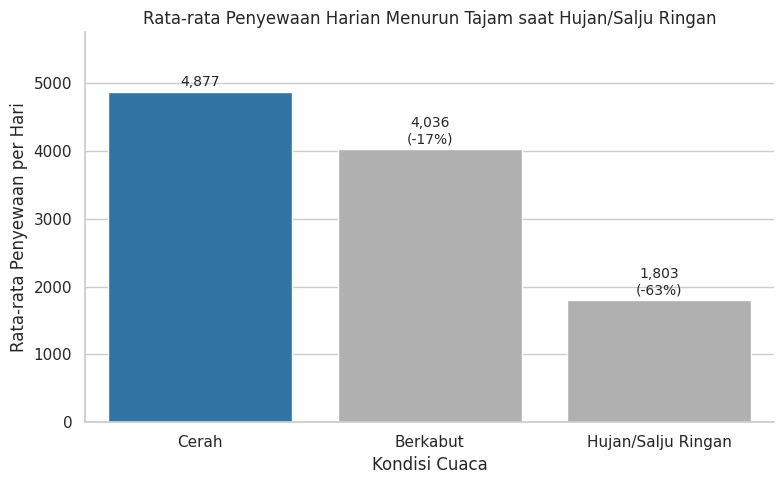

In [23]:
urutan = ['Cerah', 'Berkabut', 'Hujan/Salju Ringan']
data_cuaca = df_day.groupby('weathersit', as_index=False)['cnt'].mean().set_index('weathersit').loc[urutan].reset_index()
warna = ['#1f77b4', '#b0b0b0', '#b0b0b0']

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=data_cuaca, x='weathersit', y='cnt', palette=warna, hue='weathersit', legend=False, ax=ax)
base = data_cuaca.loc[0, 'cnt']
for i, v in enumerate(data_cuaca['cnt']):
    label = f'{v:,.0f}' if i == 0 else f'{v:,.0f}\n({(v/base-1)*100:.0f}%)'
    ax.text(i, v + 80, label, ha='center', fontsize=10)
ax.set_title('Rata-rata Penyewaan Harian Menurun Tajam saat Hujan/Salju Ringan', fontsize=12)
ax.set_xlabel('Kondisi Cuaca')
ax.set_ylabel('Rata-rata Penyewaan per Hari')
ax.set_ylim(0, data_cuaca['cnt'].max() * 1.18)
sns.despine()
plt.tight_layout()
plt.show()

**Insight Pertanyaan 1:**
- Rata-rata penyewaan saat cuaca cerah ±4.877 per hari, turun menjadi ±4.036 saat berkabut (**-17%**) dan ±1.803 saat hujan/salju ringan (**-63%**).

### Pertanyaan 2: Rata-rata penyewaan harian per musim

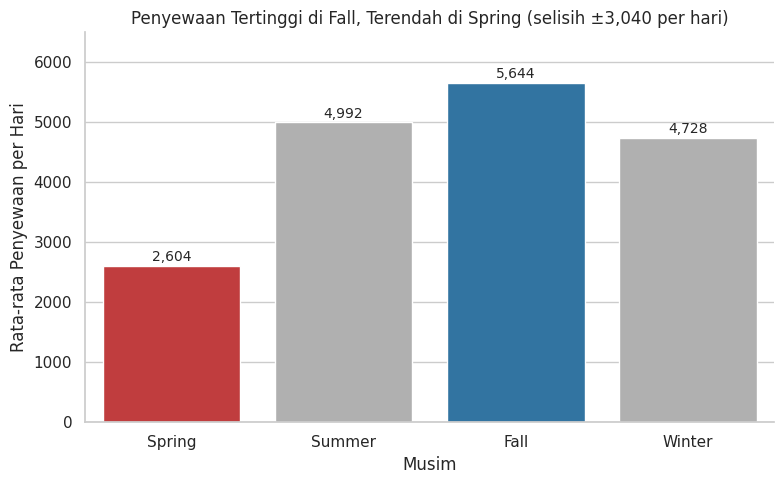

In [24]:
urutan_musim = ['Spring', 'Summer', 'Fall', 'Winter']
data_musim = df_day.groupby('season', as_index=False)['cnt'].mean().set_index('season').loc[urutan_musim].reset_index()
tertinggi, terendah = data_musim['cnt'].idxmax(), data_musim['cnt'].idxmin()
warna = ['#b0b0b0'] * 4
warna[tertinggi] = '#1f77b4'
warna[terendah] = '#d62728'

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=data_musim, x='season', y='cnt', palette=warna, hue='season', legend=False, ax=ax)
for i, v in enumerate(data_musim['cnt']):
    ax.text(i, v + 80, f'{v:,.0f}', ha='center', fontsize=10)
selisih = data_musim['cnt'].max() - data_musim['cnt'].min()
ax.set_title(f'Penyewaan Tertinggi di Fall, Terendah di Spring (selisih ±{selisih:,.0f} per hari)', fontsize=12)
ax.set_xlabel('Musim')
ax.set_ylabel('Rata-rata Penyewaan per Hari')
ax.set_ylim(0, data_musim['cnt'].max() * 1.15)
sns.despine()
plt.tight_layout()
plt.show()

**Insight Pertanyaan 2:**

- Rata-rata penyewaan harian tertinggi terjadi pada musim **Fall** (±5.644) dan terendah pada **Spring** (±2.604), selisih ±3.040 penyewaan per hari.
- Fall sekitar **2,2 kali** lebih ramai daripada Spring, sedangkan Summer (±4.992) dan Winter (±4.728) berada di tengah.

## Analisis Lanjutan: Clustering Manual (Binning)

**Tujuan:** mengelompokkan hari ke dalam tingkat permintaan (Rendah, Sedang, Tinggi) berdasarkan kuartil `cnt` tanpa algoritma *machine learning*, lalu melihat kondisi cuaca dan musim yang dominan pada tiap kelompok. Hasilnya dipakai untuk mengenali kondisi yang biasanya menghasilkan permintaan rendah atau tinggi.

Batas binning: Rendah <= 3152, Sedang 3152-5956, Tinggi > 5956

Jumlah hari per kelompok:


,count
kelompok_permintaan,
Rendah,183
Sedang,365
Tinggi,183


weathersit,Berkabut,Cerah,Hujan/Salju Ringan
kelompok_permintaan,,,
Rendah,43.2,46.4,10.4
Sedang,34.5,64.9,0.5
Tinggi,23.0,77.0,0.0


season,Fall,Spring,Summer,Winter
kelompok_permintaan,,,,
Rendah,2.2,66.7,15.3,15.8
Sedang,28.8,14.8,25.8,30.7
Tinggi,43.2,2.7,33.9,20.2


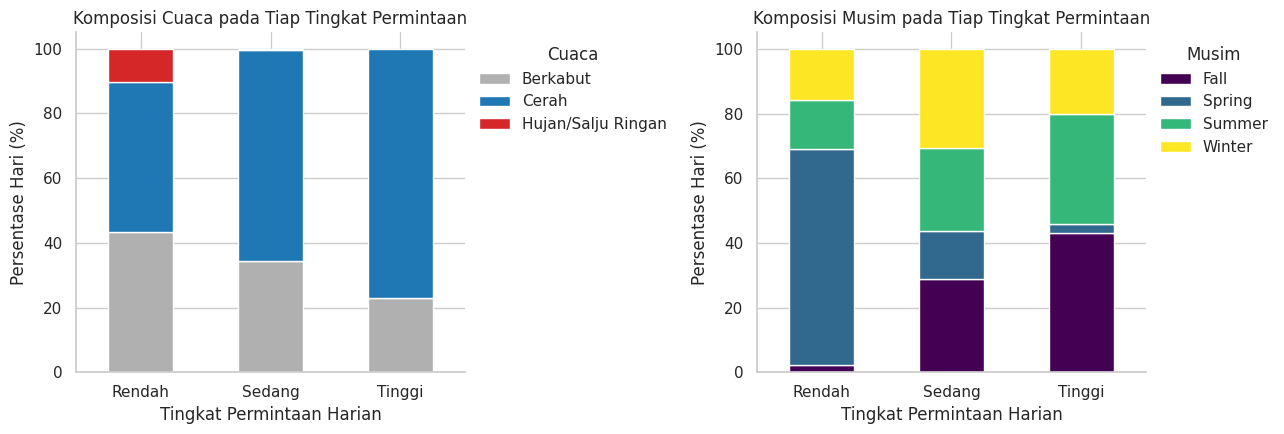

In [25]:
# Binning: tingkat permintaan harian berdasarkan kuartil cnt
q1, q3 = df_day['cnt'].quantile([0.25, 0.75])
df_day['kelompok_permintaan'] = pd.cut(df_day['cnt'], bins=[0, q1, q3, df_day['cnt'].max()],
                                       labels=['Rendah', 'Sedang', 'Tinggi'], include_lowest=True)
print(f'Batas binning: Rendah <= {q1:.0f}, Sedang {q1:.0f}-{q3:.0f}, Tinggi > {q3:.0f}')
print('\nJumlah hari per kelompok:')
display(df_day['kelompok_permintaan'].value_counts().reindex(['Rendah', 'Sedang', 'Tinggi']))

cuaca_vs = pd.crosstab(df_day['kelompok_permintaan'], df_day['weathersit'], normalize='index').mul(100).round(1)
musim_vs = pd.crosstab(df_day['kelompok_permintaan'], df_day['season'], normalize='index').mul(100).round(1)
display(cuaca_vs); display(musim_vs)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
cuaca_vs.plot(kind='bar', stacked=True, ax=axes[0], color=['#1f77b4', '#b0b0b0', '#d62728'][::-1] if False else ['#b0b0b0', '#1f77b4', '#d62728'], rot=0)
axes[0].set_title('Komposisi Cuaca pada Tiap Tingkat Permintaan')
axes[0].set_xlabel('Tingkat Permintaan Harian'); axes[0].set_ylabel('Persentase Hari (%)'); axes[0].legend(title='Cuaca', frameon=False, bbox_to_anchor=(1, 1))
musim_vs.plot(kind='bar', stacked=True, ax=axes[1], colormap='viridis', rot=0)
axes[1].set_title('Komposisi Musim pada Tiap Tingkat Permintaan')
axes[1].set_xlabel('Tingkat Permintaan Harian'); axes[1].set_ylabel('Persentase Hari (%)'); axes[1].legend(title='Musim', frameon=False, bbox_to_anchor=(1, 1))
sns.despine(); plt.tight_layout(); plt.show()

**Insight:** (Opsional)

- Hari dengan permintaan **Rendah** didominasi musim Spring (±67%), dan ±54% di antaranya jatuh pada cuaca berkabut atau hujan/salju ringan.
- Hari dengan permintaan **Tinggi** terkonsentrasi di Fall (±43%) dan Summer (±34%), dengan ±77% pada cuaca cerah dan tidak ada yang jatuh pada hujan/salju ringan.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** cuaca sangat memengaruhi jumlah penyewaan. Dibanding cuaca cerah (±4.877/hari), cuaca berkabut menurunkan rata-rata penyewaan ±17% dan hujan/salju ringan ±63% (±1.803/hari). Catatan: hanya 21 hari bercuaca hujan/salju ringan, sehingga angkanya perlu dibaca dengan hati-hati.
- **Conclusion pertanyaan 2:** rata-rata penyewaan tertinggi terjadi pada musim Fall (±5.644/hari) dan terendah pada Spring (±2.604/hari), selisih ±3.040 per hari atau Fall sekitar 2,2 kali Spring.

**Rekomendasi Action Item:**
- Gunakan prakiraan cuaca untuk memperkirakan permintaan harian: hari berkabut diperkirakan sekitar 17% lebih sepi dan hari hujan/salju ringan sekitar 63% lebih sepi dibanding hari cerah.
- Susun rencana operasional mengikuti pola musiman: permintaan tertinggi di Fall dan terendah di Spring. Dataset tidak memuat data ketersediaan atau kondisi sepeda, sehingga kebutuhan sepeda dan jadwal perawatan perlu dihitung dari data operasional operator.